<a href="https://colab.research.google.com/github/Ghazal-Rouhani/DSC_110/blob/main/Data_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import pandas to read the dataset and work with the data in a table. I also import pyplot from matplotlib to make graphs.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

I use read_csv to load the NHANES dataset from the GitHub link. The data is saved in a DataFrame called df, so I can use it in the next steps.

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/nhanes_final.csv")

I check the first five rows to see what the dataset looks like and what columns it has.

In [ ]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN


Transforming Variables

The education column uses numbers instead of written categories. I use unique() to see which education codes are in the dataset before I change their labels.

In [ ]:
df['education'].unique()

array([ 5.,  3., nan,  2.,  4.,  1.,  9.])

I make a dictionary that matches each education code with a description. This will make the results easier to read instead of just showing numbers.

In [ ]:
education_map =  {
    1: 'Less than 9th grade',
    2: '9-11th grade',
    3: 'High school grad',
    4: 'Some college or AA degree',
    5: 'College grad',
    9: 'Don''t know'
}

I use map() with my dictionary to turn the education numbers into text labels. I save them in a new column so the original education column stays the same.

In [ ]:
df ['education_label'] = df['education'].map(education_map)

Here I look at the first rows again to make sure the new education_label column was added.

In [ ]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,College grad
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,College grad
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,High school grad
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN


Here I count how many people are in each education category. value_counts() helps me see which education levels are more common in the data.

In [ ]:
df['education_label'].value_counts()

,count
education_label,
College grad,2625
Some college or AA degree,2370
High school grad,1749
9-11th grade,666
Less than 9th grade,373
Dont know,11


Diabetes practice

Before changing the diabetes codes, I check the different values in this column.

In [ ]:
df['has_diabetes'].unique()

array([ 2.,  1.,  3., nan,  9.])

I match the diabetes codes with labels like Has Diabetes, No Diabetes, and Borderline.

In [ ]:
diabetes_map = {
    1: 'Has Diabetes',
    2: 'No Diabetes',
    3: 'Borderline',
    9: 'Do not know'
}

I add a diabetes_label column using the diabetes dictionary. This way I can use readable categories without removing the original numeric values.

In [ ]:
df['diabetes_label'] = df['has_diabetes'].map(diabetes_map)

Here I check the first five rows to see if the diabetes labels were added correctly.

In [ ]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label,diabetes_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,College grad,No Diabetes
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,College grad,No Diabetes
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,High school grad,Has Diabetes
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN,No Diabetes
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,No Diabetes


Here I count the number of people in each diabetes category. This gives me a quick summary of how the responses are distributed.

In [ ]:
df['diabetes_label'].value_counts()

,count
diabetes_label,
No Diabetes,10371
Has Diabetes,1081
Borderline,284
Do not know,4


Data summarization
One numerical value

Here I calculate the mean age to find the average age of the respondents. I round it to two decimal places and print the result with a sentence to make it clear.

In [ ]:
avg_age = round(df['age'].mean(),2)
print(f"The average age of NHANES respondents is {avg_age}")

The average age of NHANES respondents is 38.32


Here I calculate the standard deviation of age. It tells me how much the ages vary around the average.

In [ ]:
df['age'].std()

25.60199011389104

Here I find the median age, which is the middle value when the ages are in order. It is useful because it is less affected by very high or low ages than the mean.

In [ ]:
df['age'].median()

37.0

I find the 25th percentile (first quartile) of age. About 25% of the non-missing ages are at or below this value.

In [ ]:
df['age'].quantile([0.25])

,age
0.25,13.0


Here I find the 75th percentile (third quartile) of age. About 75% of the non-missing ages are at or below this value.

In [ ]:
df['age'].quantile([0.75])

,age
0.75,62.0


describe() gives me several age statistics at once, like count, mean, standard deviation, and quartiles. I use apply() with format() to show the numbers in regular decimal format instead of scientific notation.

In [ ]:
df['age'].describe().apply(lambda x: format (x, 'f'))
#without scientific notation

,age
count,11933.000000
mean,38.317858
std,25.601990
min,0.000000
25%,13.000000
50%,37.000000
75%,62.000000
max,80.000000


Data visualization for one numerical value

Here I make a basic histogram of age to see the distribution. The bars show how many respondents fall into different age ranges.

<Axes: >

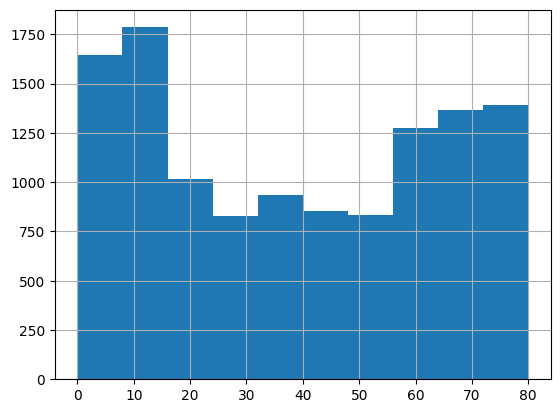

In [ ]:
df['age'].hist()

I make the age histogram again, but this time I change the bar color and add purple borders. I add a title and axis labels so it is clear what the graph is showing. I turn off the grid because the graph looks cleaner without it.

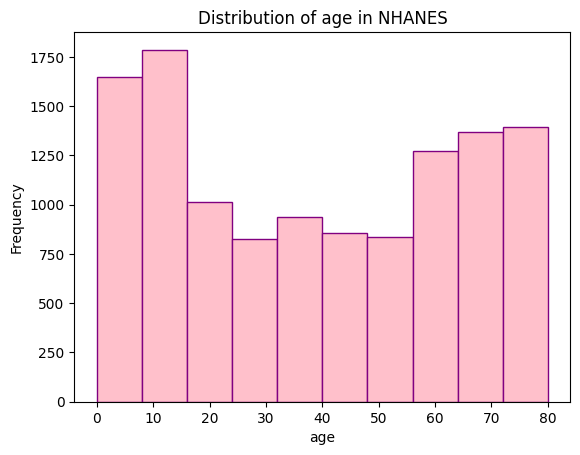

In [ ]:
df['age'].hist(edgecolor = 'purple', color = 'pink')
plt.title("Distribution of age in NHANES")
plt.ylabel("Frequency")
plt.xlabel("age")
plt.grid(False)

Summarization and visualization of one categorical/qualitative variable

I count the responses in each education category again. I will use these counts to summarize a categorical variable instead of a numerical one.

In [ ]:
df ['education_label'].value_counts()

,count
education_label,
College grad,2625
Some college or AA degree,2370
High school grad,1749
9-11th grade,666
Less than 9th grade,373
Dont know,11


I use normalize=True to get the proportion of people in each education category. Multiplying by 100 changes the proportions into percentages, which are easier to compare.

In [ ]:
df['education_label'].value_counts(normalize=True) * 100

,proportion
education_label,
College grad,33.679754
Some college or AA degree,30.408006
High school grad,22.440339
9-11th grade,8.545035
Less than 9th grade,4.785733
Dont know,0.141134


I make a bar chart from the education category counts. A bar chart is useful here because education is a categorical variable. I add a title and axis labels to explain what the categories and bar heights mean.

Text(0, 0.5, 'number of respondents/frequency')

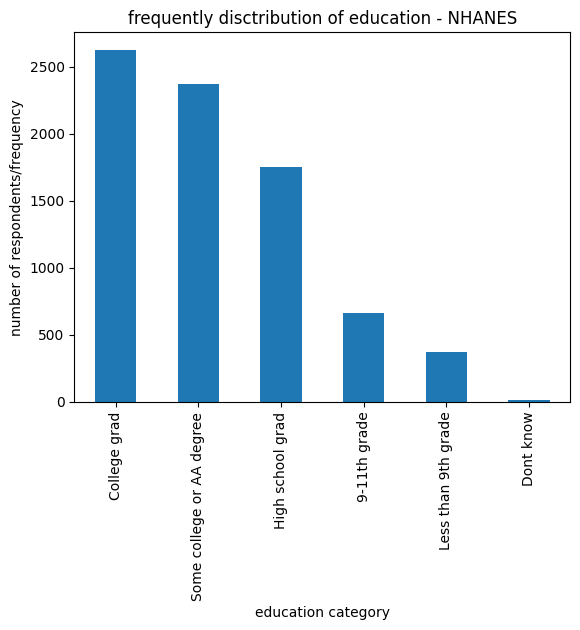

In [ ]:
df['education_label'].value_counts().plot(kind='bar')
plt.title('frequently disctribution of education - NHANES')
plt.xlabel('education category')
plt.ylabel('number of respondents/frequency')

I make a scatter plot to compare fasting glucose and HbA1c. Each point is one observation, so I can see how the two numerical variables are related.

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

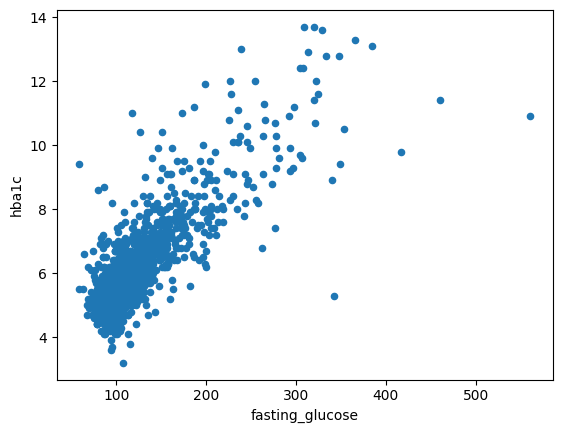

In [ ]:
df.plot(x='fasting_glucose', y='hba1c', kind='scatter')

I make a new DataFrame that only includes rows where fasting glucose is below 300. Then I make the scatter plot again to see the main pattern without the highest glucose values. I keep the original df unchanged so I can still use the full data later. This table is more people friendly and they can read it better.

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

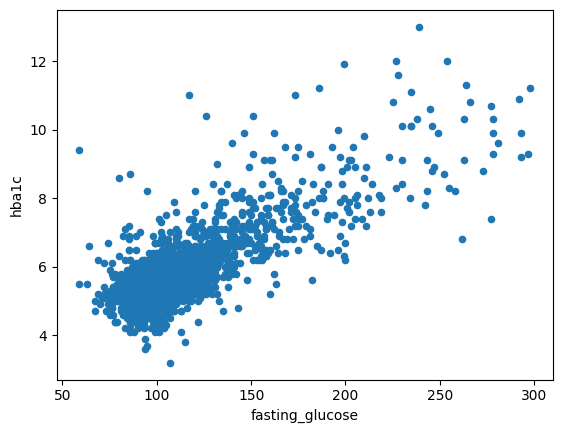

In [ ]:
df_no_outliers = df[df['fasting_glucose']<300]
df_no_outliers.plot(x='fasting_glucose', y='hba1c', kind='scatter')

Two categorical values

I use pd.cut() to put BMI values into four categories based on the listed cutoffs. The bins set the BMI ranges, and labels give each range a name. I save these groups in bmi_category so I can compare BMI categories with another categorical variable.

In [ ]:
df['bmi_category'] = pd.cut(df['bmi'],
                            bins = [0, 18.5, 25, 30, 100],
                            labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
                            )

I make a cross-tabulation to compare BMI categories with diabetes categories. normalize='index' calculates proportions within each BMI group, and multiplying by 100 gives percentages. This makes it easier to compare diabetes responses across the BMI groups even if their sizes are different.

In [ ]:
pd.crosstab(df['bmi_category'], df['diabetes_label'], normalize='index') * 100

diabetes_label,Borderline,Do not know,Has Diabetes,No Diabetes
bmi_category,,,,
Underweight,0.000000,0.082237,0.328947,99.588816
Normal,1.625000,0.041667,4.541667,93.791667
Overweight,3.197807,0.000000,10.644130,86.158063
Obese,4.501125,0.000000,18.904726,76.594149


I use a crosstab again, but this time I plot the counts as a bar chart. This lets me compare the numbers of diabetes responses across BMI categories visually.

<Axes: xlabel='bmi_category'>

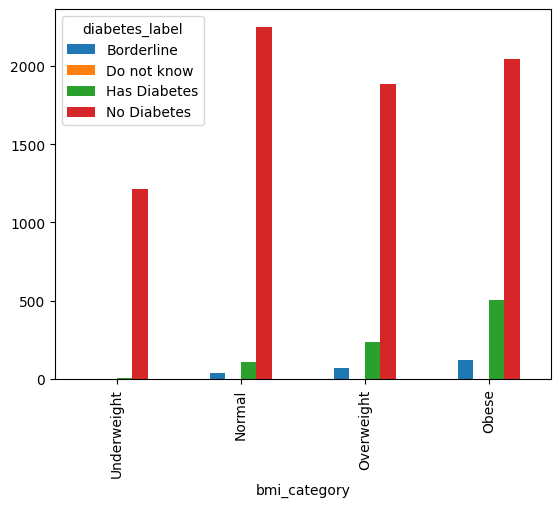

In [ ]:
pd.crosstab(df['bmi_category'], df['diabetes_label']).plot(kind='bar')

One numerical and one categorical

Here I group the data by diabetes category and calculate the average BMI in each group. This helps me compare a numerical variable (BMI) across different categories.

In [ ]:
df.groupby('diabetes_label')['bmi'].mean()

,bmi
diabetes_label,
Borderline,32.068559
Do not know,19.250000
Has Diabetes,32.981412
No Diabetes,26.439797


I make boxplots of BMI for each diabetes category. The boxes show the middle part of each BMI distribution, and the plot also helps me see the spread and possible outliers.

<Axes: title={'center': 'bmi'}, xlabel='diabetes_label'>

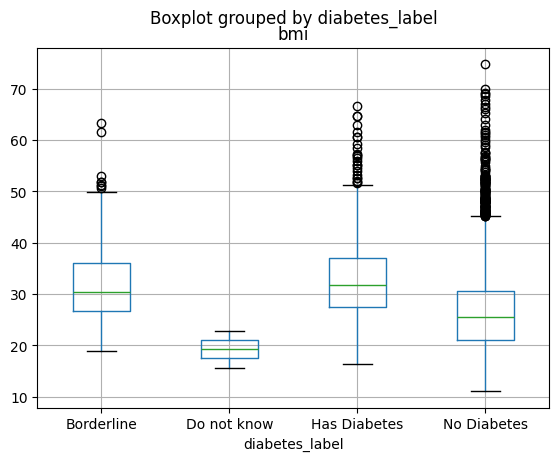

In [ ]:
df.boxplot(column ='bmi', by='diabetes_label')

Here I install the tableone package because it is not always included in a new Colab notebook. This package can make a summary table for the dataset.

In [ ]:
!pip install tableone

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.9 MB/s eta 0:00:00


I import tableone after installing it so I can use its functions.

In [ ]:
import tableone

I use TableOne to create a summary table for the variables in df. It gives me an overview of the dataset without calculating each statistic separately.

In [ ]:
tableone.TableOne (df)

Missing            Overall
n                                                                         11933
id, mean (SD)                                              0  136344.0 (3444.9)
gender, n (%)              1.0                                      5575 (46.7)
                           2.0                                      6358 (53.3)
age, mean (SD)                                             0        38.3 (25.6)
race_ethnicity, n (%)      1.0                                       1117 (9.4)
                           2.0                                      1373 (11.5)
                           3.0                                      6217 (52.1)
                           4.0                                      1597 (13.4)
                           6.0                                        681 (5.7)
                           7.0                                        948 (7.9)
education, n (%)           1.0                                        373 (3.1)
                           2.0                                        666 (5.6)
                           3.0                                      1749 (14.7)
                           4.0                                      2370 (19.9)
                           5.0                                      2625 (22.0)
                           9.0                                         11 (0.1)
                           None                                     4139 (34.7)
bmi, mean (SD)                                          3462         27.2 (8.1)
height_cm, mean (SD)                                    3434       159.7 (19.9)
systolic_bp, mean (SD)                                  4416       119.3 (18.6)
has_diabetes, n (%)        1.0                                       1081 (9.1)
                           2.0                                     10371 (86.9)
                           3.0                                        284 (2.4)
                           9.0                                          4 (0.0)
                           None                                       193 (1.6)
hba1c, mean (SD)                                        5218          5.7 (1.1)
fasting_glucose, mean (SD)                              8261       107.9 (32.5)
education_label, n (%)     9-11th grade                               666 (5.6)
                           College grad                             2625 (22.0)
                           Dont know                                   11 (0.1)
                           High school grad                         1749 (14.7)
                           Less than 9th grade                        373 (3.1)
                           None                                     4139 (34.7)
                           Some college or AA degree                2370 (19.9)
diabetes_label, n (%)      Borderline                                 284 (2.4)
                           Do not know                                  4 (0.0)
                           Has Diabetes                              1081 (9.1)
                           No Diabetes                             10371 (86.9)
                           None                                       193 (1.6)
bmi_category, n (%)        Underweight                              1216 (10.2)
                           Normal                                   2400 (20.1)
                           Overweight                               2189 (18.3)
                           Obese                                    2666 (22.3)
                           None                                     3462 (29.0)

I make another TableOne summary and put age in the nonnormal list. This tells TableOne to summarize age as a non-normal numerical variable instead of using the normal-data summary. I also turn on show_histograms to include small distribution plots in the summary where supported.

In [ ]:
tableone.TableOne(df, nonnormal=['age'], show_histograms = True)

Missing            Overall Histogram
n                                                                         11933          
id, mean (SD)                                              0  136344.0 (3444.9)  █▇▇▇▇▇▇█
gender, n (%)              1.0                                      5575 (46.7)          
                           2.0                                      6358 (53.3)          
age, median [Q1,Q3]                                        0   37.0 [13.0,62.0]  █▇▃▄▄▄▆▆
race_ethnicity, n (%)      1.0                                       1117 (9.4)          
                           2.0                                      1373 (11.5)          
                           3.0                                      6217 (52.1)          
                           4.0                                      1597 (13.4)          
                           6.0                                        681 (5.7)          
                           7.0                                        948 (7.9)          
education, n (%)           1.0                                        373 (3.1)          
                           2.0                                        666 (5.6)          
                           3.0                                      1749 (14.7)          
                           4.0                                      2370 (19.9)          
                           5.0                                      2625 (22.0)          
                           9.0                                         11 (0.1)          
                           None                                     4139 (34.7)          
bmi, mean (SD)                                          3462         27.2 (8.1)  ▅▆█▆▃▂▁▁
height_cm, mean (SD)                                    3434       159.7 (19.9)  ▁▁▁▁▃█▇▃
systolic_bp, mean (SD)                                  4416       119.3 (18.6)  ▃▆█▅▃▂▁▁
has_diabetes, n (%)        1.0                                       1081 (9.1)          
                           2.0                                     10371 (86.9)          
                           3.0                                        284 (2.4)          
                           9.0                                          4 (0.0)          
                           None                                       193 (1.6)          
hba1c, mean (SD)                                        5218          5.7 (1.1)  ▄█▂▁▁▁▁▁
fasting_glucose, mean (SD)                              8261       107.9 (32.5)  █▅▁▁▁▁▁▁
education_label, n (%)     9-11th grade                               666 (5.6)          
                           College grad                             2625 (22.0)          
                           Dont know                                   11 (0.1)          
                           High school grad                         1749 (14.7)          
                           Less than 9th grade                        373 (3.1)          
                           None                                     4139 (34.7)          
                           Some college or AA degree                2370 (19.9)          
diabetes_label, n (%)      Borderline                                 284 (2.4)          
                           Do not know                                  4 (0.0)          
                           Has Diabetes                              1081 (9.1)          
                           No Diabetes                             10371 (86.9)          
                           None                                       193 (1.6)          
bmi_category, n (%)        Underweight                              1216 (10.2)          
                           Normal                                   2400 (20.1)          
                           Overweight                               2189 (18.3)          
                           Obese                                    2666 (22.3)          
   